# Módulo 14 — Calibração II: saltos, regularização e o BCC97 completo

## Introdução

O capítulo anterior mostrou que a calibração pode ser instável: pequenas mudanças nos preços de mercado podem mover muito os parâmetros. Na terminologia matemática, ela é um **problema mal posto**. Este capítulo trata do remédio clássico, a **regularização**: acrescentar ao erro de ajuste uma penalidade que prende os parâmetros a uma referência, como a calibração da véspera, trocando um pouco de ajuste por muita estabilidade.

Em seguida, os saltos entram na calibração. Saltos e volatilidade estocástica produzem skews parecidos, mas com assinaturas diferentes ao longo dos prazos: os saltos dominam os vencimentos curtos e a volatilidade estocástica os longos. O capítulo compara a calibração sequencial (um bloco de cada vez) com a calibração conjunta do BCC97 completo.

Por fim, o capítulo mede o **risco de modelo** que sobra depois de uma boa calibração: conjuntos de parâmetros que ajustam o mercado igualmente bem podem dar preços diferentes para contratos que dependem de aspectos que as opções calibradas não revelam.

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** capítulo 11 do livro, §11.4.4 a §11.6.6.

## O que você vai conseguir fazer ao final

1. Explicar por que calibrar saltos é um problema mal posto e o que a regularização de Tikhonov faz.
2. Distinguir a penalidade quadrática da penalidade em norma do livro, e prever quando a segunda congela os parâmetros.
3. Reproduzir o roteiro sequencial do livro (Heston, saltos, BCC97 completo) e ver onde ele falha.
4. Mapear a degenerescência entre intensidade e tamanho dos saltos.
5. Medir o efeito da regularização na estabilidade de recalibrações.
6. Calibrar a volatilidades implícitas e entender por que (11.4) quase não muda nada.
7. Medir o risco de modelo que sobra depois de uma calibração bem-sucedida.

## Onde estamos

O Módulo 13 calibrou o CIR e o Heston, e deixou dois recados: o resíduo do Heston se concentra no prazo curto, onde os saltos deveriam ajudar, e nem todo parâmetro é identificado pelos dados. Este módulo completa o capítulo 11 com os saltos e o modelo geral, no mesmo mercado sintético.

## 0. Preparação

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.interpolate as sci
from scipy.integrate import simpson
from scipy.optimize import brentq, brute, fmin, linprog
from scipy.stats import norm
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
RAMPA = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def bsm(S, K, T, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d1 - sig * np.sqrt(T))


def vega_bsm(S, K, T, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    return S * norm.pdf(d1) * np.sqrt(T)


def vol_impl(preco, S, K, T, r):
    piso = max(S - K * np.exp(-r * T), 0.0)
    if not (piso + 1e-12 < preco < S):
        return np.nan
    return brentq(lambda s: float(bsm(S, K, T, r, s)) - preco, 1e-4, 4.0)


def cf_heston(u, T, v0, kappa, theta, sigma, rho):
    """Função característica de ln(S_T/S_0) - rT no Heston, forma estável (Módulo 11)."""
    xi = kappa - rho * sigma * 1j * u
    d = np.sqrt(xi**2 + sigma**2 * (1j * u + u**2))
    g = (xi - d) / (xi + d)
    e = np.exp(-d * T)
    A = kappa * theta / sigma**2 * ((xi - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    B = (xi - d) / sigma**2 * (1 - e) / (1 - g * e)
    return np.exp(A + B * v0)


def cf_saltos(u, T, lam, mu, delta):
    """Parte de saltos de Merton, com o drift compensado (11.13)-(11.14)."""
    omega = -lam * (np.exp(mu + 0.5 * delta**2) - 1)
    return np.exp((1j * u * omega + lam * (np.exp(1j * u * mu - 0.5 * u**2 * delta**2) - 1)) * T)


U_FINO = np.linspace(0, 2000, 200_001)
U_CAL = np.linspace(0, 300, 3001)


def calls(S0, K, T, r, heston, saltos=None, u=U_CAL):
    """Calls europeias pela fórmula de Lewis (11.12), vetorizada em (K, T, r) do mesmo tamanho.
    heston = (v0, κ_v, θ_v, σ_v, ρ); saltos = (λ, μ_J, δ) ou None."""
    K, T, r = (np.atleast_1d(np.asarray(x, float)) for x in (K, T, r))
    k = np.log(S0 / K) + r * T
    phi = cf_heston(u[None, :] - 0.5j, T[:, None], *heston)
    if saltos is not None:
        phi = phi * cf_saltos(u[None, :] - 0.5j, T[:, None], *saltos)
    h = np.exp(1j * u[None, :] * k[:, None]) * phi
    integral = simpson(h.real / (u**2 + 0.25), x=u, axis=1)
    return S0 - np.sqrt(S0 * K) * np.exp(-0.5 * r * T) / np.pi * integral


def zcb_cir(r0, kappa, theta, sigma, T):
    """Zero-cupom no CIR, (11.7)-(11.9) com t = 0."""
    g = np.sqrt(kappa**2 + 2 * sigma**2)
    e = np.exp(g * T) - 1
    D = 2 * g + (kappa + g) * e
    return (2 * g * np.exp((kappa + g) * T / 2) / D) ** (2 * kappa * theta / sigma**2) * np.exp(-2 * e / D * r0)


print("Ambiente pronto.")

Ambiente pronto.


### O mercado sintético do Módulo 13

As mesmas 15 calls: $S_0 = 3.225{,}93$; 17, 80 e 171 dias; strikes de 3.000 a 3.400. O modelo verdadeiro é o Bates ($v_0 = 0{,}03$, $\kappa_v = 3$, $\theta_v = 0{,}04$, $\sigma_v = 0{,}5$, $\rho = -0{,}7$, $\lambda = 0{,}15$, $\mu_J = -0{,}15$, $\delta = 0{,}1$), e as cotações são arredondadas a 0,1 ponto. Os juros vêm da curva CIR; no Módulo 13, a calibração com a fórmula correta reproduziu a curva com erro abaixo de 0,1 pb, então usamos a curva verdadeira.

Para não depender do Módulo 13, refazemos aqui a calibração do Heston (grade do livro + Nelder-Mead), que é o ponto de partida do livro para os saltos.

Um detalhe prático aparece já aqui. Com os juros da curva verdadeira em vez dos da curva calibrada (diferença abaixo de 0,1 pb), o Nelder-Mead do mesmo ponto da grade **para** num EQM de 0,8, e não de 0,09 como no Módulo 13. O simplex encosta na parede de Feller (onde a função vale 500), se achata e declara convergência. A correção usual é **reiniciar** a busca a partir do ponto encontrado, com um simplex novo. Fazemos isso abaixo.

In [2]:
S0 = 3225.93
DIAS = np.array([17, 80, 171])
STRIKES = np.arange(3000, 3401, 100.0)
T_OP = np.repeat(DIAS / 365, 5)
K_OP = np.tile(STRIKES, 3)
CURTO = T_OP == T_OP.min()
CIR_VERDADE = dict(r0=0.02, kappa=0.5, theta=0.045, sigma=0.08)
R_OP = -np.log(zcb_cir(T=T_OP, **CIR_VERDADE)) / T_OP

HESTON_VERDADE = (0.03, 3.0, 0.04, 0.5, -0.7)          # (v0, κ_v, θ_v, σ_v, ρ)
SALTOS_VERDADE = (0.15, -0.15, 0.10)                   # (λ, μ_J, δ)
C_JUSTO = calls(S0, K_OP, T_OP, R_OP, HESTON_VERDADE, SALTOS_VERDADE, U_FINO)
C_MERC = np.round(C_JUSTO, 1)
IV_MERC = np.array([vol_impl(c, S0, k, t, r) for c, k, t, r in zip(C_MERC, K_OP, T_OP, R_OP)])
VEGA = vega_bsm(S0, K_OP, T_OP, R_OP, IV_MERC)

# Vetor completo do BCC97 (com juros por vencimento): p = (κ_v, θ_v, σ_v, ρ, v0, λ, μ_J, δ)
NOMES = ["κ_v", "θ_v", "σ_v", "ρ", "v0", "λ", "μ_J", "δ"]
VERDADE = np.array([3.0, 0.04, 0.5, -0.7, 0.03, 0.15, -0.15, 0.10])


def admissivel(p, feller):
    kappa, theta, sigma, rho, v0, lam, mu, delta = p
    if (kappa < 0 or theta < 0.005 or sigma < 0 or abs(rho) > 1 or v0 < 0
            or lam < 0 or mu < -0.6 or mu > 0 or delta < 0):
        return False
    return not (feller and 2 * kappa * theta < sigma**2)


def precos_bcc(p, mascara=slice(None), u=U_CAL):
    kappa, theta, sigma, rho, v0, lam, mu, delta = p
    return calls(S0, K_OP[mascara], T_OP[mascara], R_OP[mascara], (v0, kappa, theta, sigma, rho), (lam, mu, delta), u)


def eqm_bcc(p, feller=False, alvo=C_MERC):
    """Função objetivo (11.1) do BCC97 completo; 5000 fora da região admissível, como no livro."""
    if not admissivel(p, feller):
        return 5000.0
    return np.mean((precos_bcc(p) - alvo) ** 2)


# Heston calibrado como no Módulo 13 (com Feller, como no livro)
def eqm_h93(q):
    return eqm_bcc(np.r_[q, 0.0, -0.1, 0.0], feller=True)


t0 = time.time()
q0 = brute(eqm_h93, ((2.5, 10.6, 5.0), (0.01, 0.041, 0.01), (0.05, 0.251, 0.1),
                     (-0.75, 0.01, 0.25), (0.01, 0.031, 0.01)), finish=None)
H93_1 = fmin(eqm_h93, q0, xtol=1e-6, ftol=1e-6, maxiter=750, maxfun=900, disp=False)
H93_CAL = fmin(eqm_h93, H93_1, xtol=1e-6, ftol=1e-6, maxiter=750, maxfun=900, disp=False)   # reinício
print("primeira busca local:", [f3(x) for x in H93_1], "| EQM", f3(eqm_h93(H93_1)))
print(f"Heston calibrado em {time.time() - t0:.1f} s:", dict(zip(NOMES[:5], [f3(x) for x in H93_CAL])),
      "| EQM", f3(eqm_h93(H93_CAL)))
ok(eqm_h93(H93_1) > 0.5, "a primeira busca local para cedo, presa na parede de Feller")
ok(eqm_h93(H93_CAL) < 0.15, "depois do reinício, o Heston reproduz o resultado do Módulo 13 (EQM perto de 0,09)")

primeira busca local: ['1,203', '0,061', '0,382', '-0,848', '0,032'] | EQM 0,808
Heston calibrado em 19.0 s: {'κ_v': '4,118', 'θ_v': '0,045', 'σ_v': '0,609', 'ρ': '-0,744', 'v0': '0,033'} | EQM 0,093
OK — a primeira busca local para cedo, presa na parede de Feller
OK — depois do reinício, o Heston reproduz o resultado do Módulo 13 (EQM perto de 0,09)


---
## 1. Problemas mal postos e regularização

**Livro: §11.4.4**

### 1.1 Os dois problemas

O livro, citando Galluccio e Le Cam (2008), aponta dois defeitos da calibração de modelos com saltos:

* **Degenerescência**: combinações diferentes de parâmetros dão o mesmo erro. Exemplo típico: muitos saltos pequenos ou poucos saltos grandes produzem skews parecidos no prazo curto.
* **Indeterminação**: a função objetivo não é convexa e tem vários mínimos locais.

Juntos, fazem o problema **mal posto** no sentido de Hadamard: a solução pode não ser única e pode não depender continuamente dos dados. Na prática, recalibrar no dia seguinte, com cotações quase iguais, pode fazer os parâmetros saltarem, e com eles as posições de hedge.

### 1.2 Tikhonov

A regularização de Tikhonov acrescenta à função objetivo um termo que puxa a solução para uma referência $p_0$ (a calibração anterior, ou o resultado da busca global):

$$\min_p\ F(p) + w\,\lVert p - p_0\rVert^2.$$

O termo quadrático é suave e estritamente convexo. Para $w$ grande o bastante, torna o problema convexo perto de $p_0$, e a solução passa a depender continuamente dos dados.

### 1.3 O que o livro faz de fato

A penalidade (11.17) é $\sqrt{\sum(p_0 - p)^2} = \lVert p - p_0\rVert$: a **norma**, não o quadrado. A diferença não é cosmética.

**Passo 1.** Em $p = p_0$, a norma tem um bico: não é diferenciável. Seu subgradiente é a bola $\{g : \lVert g\rVert \le 1\}$.

**Passo 2.** $p_0$ é mínimo de $F(p) + w\lVert p - p_0\rVert$ se e só se $0 \in \nabla F(p_0) + w\,\{g : \lVert g\rVert \le 1\}$, isto é, se

$$\lVert\nabla F(p_0)\rVert \le w.$$

**Passo 3.** Interpretação: a norma é uma **penalidade exata**. Enquanto a inclinação da função objetivo em $p_0$ for menor que $w$, os parâmetros **não saem do lugar**. Com o EQM em pontos² da ordem de $10^{-2}$ e $w = 1$, essa é a situação típica: a "calibração local" devolve o ponto de partida.

### Laboratório 1 — As duas penalidades num exemplo de uma dimensão

Com $F(p) = (p - 1)^2$ e $p_0 = 0$:

* quadrática: $\min (p - 1)^2 + wp^2 \Rightarrow p^* = 1/(1 + w)$, que se aproxima de zero devagar;
* norma: $\min (p - 1)^2 + w|p| \Rightarrow p^* = \max(0,\ 1 - w/2)$, que chega a zero e para lá a partir de $w = 2 = |F'(0)|$.

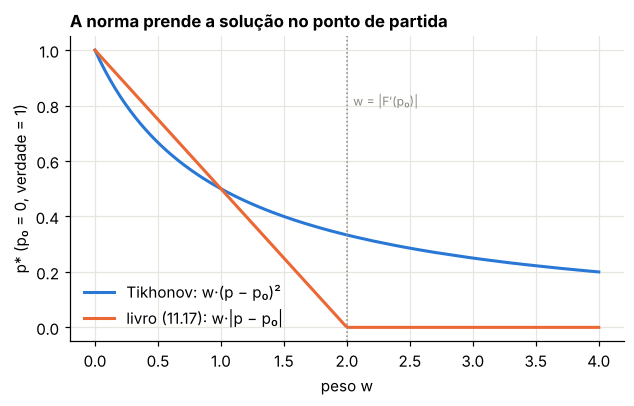

OK — Tikhonov: p* = 1/(1+w)
OK — norma: p* = max(0, 1 − w/2)
OK — com w ≥ |F'(p₀)| a solução com a norma fica exatamente em p₀


In [3]:
ws = np.linspace(0, 4, 200)
grade_p = np.linspace(-0.5, 1.5, 20001)
p_quad = [grade_p[np.argmin((grade_p - 1) ** 2 + w * grade_p**2)] for w in ws]
p_norm = [grade_p[np.argmin((grade_p - 1) ** 2 + w * np.abs(grade_p))] for w in ws]

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(ws, p_quad, color=AZUL, label="Tikhonov: w·(p − p₀)²")
ax.plot(ws, p_norm, color=LARANJA, label="livro (11.17): w·|p − p₀|")
ax.axvline(2, color=CINZA, ls=":", lw=1)
ax.text(2.05, 0.8, "w = |F′(p₀)|", color=CINZA, fontsize=8)
ax.set_xlabel("peso w"); ax.set_ylabel("p* (p₀ = 0, verdade = 1)")
ax.set_title("A norma prende a solução no ponto de partida")
ax.legend(); plt.show()

ok(np.allclose(p_quad, 1 / (1 + ws), atol=2e-4), "Tikhonov: p* = 1/(1+w)")
ok(np.allclose(p_norm, np.maximum(0, 1 - ws / 2), atol=2e-4), "norma: p* = max(0, 1 − w/2)")
ok(np.all(np.array(p_norm)[ws >= 2] == 0), "com w ≥ |F'(p₀)| a solução com a norma fica exatamente em p₀")

---
## 2. Calibrar só os saltos

**Livro: §11.4.4 e §11.6.4**

### 2.1 O roteiro do livro

1. Fixe os parâmetros de volatilidade estocástica no resultado do Heston.
2. Calibre $(\lambda, \mu_J, \delta)$ às 5 opções de 17 dias: grade ($\lambda \in \{0; 0{,}1; \dots; 0{,}5\}$, $\mu_J \in \{-0{,}5; \dots; -0{,}2\}$, $\delta \in \{0;\ 0{,}25;\ 0{,}5\}$), depois Nelder-Mead **com a penalidade** (11.17) em torno do ponto da grade.

Restrições: $\lambda \ge 0$, $-0{,}6 \le \mu_J \le 0$, $\delta \ge 0$.

### 2.2 Um detalhe de Python: a penalidade nunca é aplicada

No script da §11.6.4, a função objetivo lê duas variáveis globais, `local_opt` (começa `False`) e `opt1`. A função de calibração faz `opt1 = brute(...)` e depois `local_opt = True`, **sem** declarar `global`. Em Python, atribuir a um nome dentro de uma função cria uma variável **local**. A global `local_opt` continua `False`, e o ramo da penalidade nunca roda. (Se rodasse, `opt1` global nem existiria.)

### Laboratório 2a — O escopo das variáveis, em miniatura

In [4]:
local_opt = False      # global, como no script do livro
chamadas = []


def erro_livro(p):
    chamadas.append(local_opt)          # o que a função objetivo enxerga
    return p**2


def calibracao_livro():
    opt1 = 0.5                          # local
    local_opt = True                    # local! não muda a global
    return erro_livro(opt1)


calibracao_livro()
print("local_opt visto pela função objetivo:", chamadas)
ok(chamadas == [False], "a atribuição sem 'global' não liga a penalidade: o livro calibra sem regularização")

local_opt visto pela função objetivo: [False]
OK — a atribuição sem 'global' não liga a penalidade: o livro calibra sem regularização


### Laboratório 2b — Os saltos sobre o Heston calibrado

Seguimos o roteiro do livro: volatilidade estocástica fixa no Heston calibrado, grade e Nelder-Mead nas 5 opções de 17 dias. Como a penalidade do livro não roda, rodamos sem ela.

In [5]:
def eqm_saltos(j, sv, alvo, pen=None, w=0.0, ref=None):
    lam, mu, delta = j
    if lam < 0 or mu < -0.6 or mu > 0 or delta < 0:
        return 5000.0
    e = np.mean((precos_bcc(np.r_[sv, j], CURTO) - alvo) ** 2)
    if pen is not None:
        d = np.asarray(j) - ref
        e += w * (np.sqrt(d @ d) if pen == "norma" else d @ d)
    return e


GRADE_SALTOS = ((0.0, 0.51, 0.1), (-0.5, -0.11, 0.1), (0.0, 0.51, 0.25))
j0 = brute(eqm_saltos, GRADE_SALTOS, args=(H93_CAL, C_MERC[CURTO]), finish=None)
j_seq = fmin(eqm_saltos, j0, args=(H93_CAL, C_MERC[CURTO]), xtol=1e-7, ftol=1e-7, maxiter=550, maxfun=750, disp=False)
sem = eqm_saltos([0.0, -0.1, 0.0], H93_CAL, C_MERC[CURTO])
print("melhor ponto da grade:", [f3(x) for x in j0], "| após Nelder-Mead:", [f3(x) for x in j_seq])
print("EQM dos 17 dias — sem saltos:", f3(sem), "| com os saltos calibrados:", f3(eqm_saltos(j_seq, H93_CAL, C_MERC[CURTO])))
ok(j_seq[0] * abs(j_seq[1]) < 0.01, "os saltos calibrados são desprezíveis: λ·|μ_J| < 0,01")
ok(eqm_saltos(j_seq, H93_CAL, C_MERC[CURTO]) > 0.9 * sem, "e quase não melhoram o ajuste dos 17 dias")

melhor ponto da grade: ['0,000', '-0,500', '0,000'] | após Nelder-Mead: ['0,000', '-0,506', '0,000']
EQM dos 17 dias — sem saltos: 0,224 | com os saltos calibrados: 0,224
OK — os saltos calibrados são desprezíveis: λ·|μ_J| < 0,01
OK — e quase não melhoram o ajuste dos 17 dias


O mercado tem saltos ($\lambda = 0{,}15$, $\mu_J = -0{,}15$), mas a calibração sequencial não os encontra. O motivo: ao calibrar o Heston sozinho, $\sigma_v$ e $\rho$ já foram esticados para produzir o skew curto. Sobre esse Heston, qualquer salto adicional piora o ajuste.

O livro chega ao mesmo lugar com dados reais: $\lambda = 0{,}008$, $\mu_J = -0{,}600$ (o limite inferior) e $\delta = 0{,}001$, ou seja, um salto de $-45\%$ a cada 125 anos. Na prática, nenhum salto.

---
## 3. O BCC97 completo

**Livro: §11.4.5 e §11.6.5**

O último passo do livro é uma busca local nos 8 parâmetros, partindo de (Heston calibrado, saltos calibrados), com a condição de Feller. Como a partida já é um mínimo local razoável, o Nelder-Mead tende a ficar perto dela.

Testamos três pontos de partida, com e sem Feller:

* **sequencial (livro)**: Heston calibrado e os saltos da Seção 2;
* **chute com saltos**: o mesmo Heston, com saltos moderados $(0{,}2;\ -0{,}1;\ 0{,}1)$;
* **verdade**: só para referência.

### Laboratório 3 — Partidas, Feller e mínimos locais

In [6]:
partidas = {"sequencial (livro)": np.r_[H93_CAL, j_seq],
            "chute com saltos": np.r_[H93_CAL, 0.2, -0.1, 0.1],
            "verdade": VERDADE}
t0 = time.time()
resultados = {}
for feller in (True, False):
    for nome, p_ini in partidas.items():
        if nome == "verdade" and feller:
            continue
        p = fmin(eqm_bcc, p_ini, args=(feller,), xtol=1e-6, ftol=1e-6, maxiter=2000, maxfun=3000, disp=False)
        resultados[(nome, "com Feller" if feller else "sem Feller")] = p
print(f"tempo: {time.time() - t0:.1f} s")
tab3 = pd.DataFrame({f"{a} / {b}": p for (a, b), p in resultados.items()}, index=NOMES).T
tab3["EQM"] = [eqm_bcc(p) for p in resultados.values()]
tab3.loc["verdade (EQM só do arredondamento)"] = list(VERDADE) + [eqm_bcc(VERDADE)]
tabela(tab3)

tempo: 103.2 s


,κ_v,θ_v,σ_v,ρ,v0,λ,μ_J,δ,EQM
sequencial (livro) / com Feller,"4,119","0,045","0,609","-0,744","0,033","0,000","-0,592","0,000","0,093"
chute com saltos / com Feller,"4,087","0,036","0,463","-0,781","0,030","0,090","-0,206","0,183","0,004"
sequencial (livro) / sem Feller,"4,119","0,045","0,609","-0,744","0,033","0,000","-0,518","0,000","0,093"
chute com saltos / sem Feller,"2,845","0,040","0,500","-0,702","0,030","0,223","-0,105","0,109","0,001"
verdade / sem Feller,"2,888","0,040","0,498","-0,699","0,030","0,191","-0,124","0,105","0,000"
verdade (EQM só do arredondamento),"3,000","0,040","0,500","-0,700","0,030","0,150","-0,150","0,100","0,001"


In [7]:
P_SEQ = resultados[("sequencial (livro)", "com Feller")]
P_JOINT = resultados[("chute com saltos", "sem Feller")]
eqm_por_prazo = pd.DataFrame({
    "Heston (Módulo 13)": [np.mean((precos_bcc(np.r_[H93_CAL, 0, -0.1, 0])[T_OP == d / 365] - C_MERC[T_OP == d / 365]) ** 2) for d in DIAS],
    "BCC97 sequencial, com Feller": [np.mean((precos_bcc(P_SEQ)[T_OP == d / 365] - C_MERC[T_OP == d / 365]) ** 2) for d in DIAS],
    "BCC97 com saltos, sem Feller": [np.mean((precos_bcc(P_JOINT)[T_OP == d / 365] - C_MERC[T_OP == d / 365]) ** 2) for d in DIAS],
}, index=[f"{d} dias" for d in DIAS])
tabela(eqm_por_prazo)

e = tab3["EQM"]
ok(e["chute com saltos / sem Feller"] < e["sequencial (livro) / com Feller"] / 10,
   "partindo com saltos e sem Feller, o EQM cai mais de 10 vezes em relação ao roteiro do livro")
ok(e["chute com saltos / sem Feller"] < 2 * e["verdade (EQM só do arredondamento)"],
   "e chega ao nível do erro de arredondamento das cotações")
ok(e["sequencial (livro) / sem Feller"] > 5 * e["chute com saltos / sem Feller"],
   "mesmo sem Feller, a partida sequencial para num mínimo local pior")
ok(abs(P_JOINT[0] - 3) < 0.5 and abs(P_JOINT[2] - 0.5) < 0.05, "o ajuste conjunto recupera κ_v e σ_v aproximadamente")

,Heston (Módulo 13),"BCC97 sequencial, com Feller","BCC97 com saltos, sem Feller"
17 dias,"0,224","0,224","0,001"
80 dias,"0,043","0,043","0,000"
171 dias,"0,011","0,011","0,000"


OK — partindo com saltos e sem Feller, o EQM cai mais de 10 vezes em relação ao roteiro do livro
OK — e chega ao nível do erro de arredondamento das cotações
OK — mesmo sem Feller, a partida sequencial para num mínimo local pior
OK — o ajuste conjunto recupera κ_v e σ_v aproximadamente


**O que aprendemos.**

* O roteiro sequencial do livro (Heston primeiro, saltos depois, busca local no fim) prende a calibração num mínimo local: os saltos nunca entram de verdade. O resultado ($\lambda = 0$, $\mu_J$ encostado no limite de $-0{,}6$, $\delta = 0$) tem a mesma cara do resultado do livro com dados reais.
* Com uma partida que já tem saltos, e sem a restrição de Feller, o ajuste chega ao nível do ruído de arredondamento das cotações e recupera os parâmetros de volatilidade.
* O melhor antídoto contra a indeterminação é barato: **várias partidas** e comparar os mínimos. Com 8 parâmetros, uma única busca local não basta.
* Os resultados do livro mostram os sinais desse problema: no BCC97 completo, $\rho = -0{,}999$ e $\delta = 0{,}000$ (dois parâmetros na fronteira) e $\lambda = 0{,}008$.

### 3.1 A degenerescência dos saltos

Mesmo no ajuste conjunto, $\lambda$ e $\mu_J$ não são recuperados separadamente com precisão. No prazo curto, o skew depende sobretudo do **produto**: a média dos saltos por ano, $\lambda\,(e^{\mu_J + \delta^2/2} - 1)$, que é a correção de drift $-\omega$ de (11.14). O mapa do erro (com $\delta$ fixo no valor calibrado) mostra um vale estreito ao longo de $\lambda\mu_J \approx$ constante. Chamamos de "fundo do vale" os pontos com EQM abaixo de 0,05, um erro típico de 0,2 ponto (dois ticks), bem menor que o 0,22 que o Heston sem saltos deixa nesse prazo.

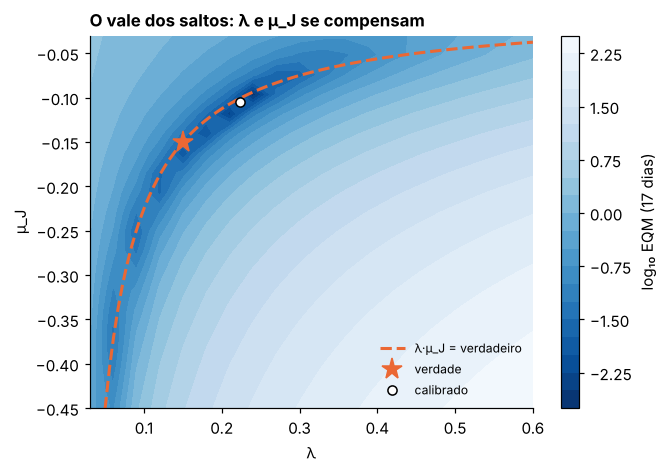

pontos no fundo do vale (EQM < 0,05): 15 | λ entre 0,060 e 0,300 | λ·μ_J entre -0,026 e -0,020
OK — no fundo do vale, λ varia por um fator maior que 2
amplitude relativa — λ: 1,364 | λ·μ_J: 0,260
OK — enquanto o produto λ·μ_J varia, em termos relativos, menos de um terço


In [8]:
SV_J = P_JOINT[:5]
lams = np.linspace(0.03, 0.6, 20)
mus = np.linspace(-0.45, -0.03, 20)
Z = np.array([[eqm_saltos([l, m, P_JOINT[7]], SV_J, C_MERC[CURTO]) for l in lams] for m in mus])

fig, ax = plt.subplots(figsize=(6.5, 4.4))
cs = ax.contourf(lams, mus, np.log10(Z), levels=20, cmap="Blues_r")
plt.colorbar(cs, ax=ax, label="log₁₀ EQM (17 dias)")
lin = np.linspace(0.05, 0.6, 100)
ax.plot(lin, VERDADE[5] * VERDADE[6] / lin, "--", color=LARANJA, label="λ·μ_J = verdadeiro")
ax.plot(*VERDADE[5:7], "*", color=LARANJA, ms=14, label="verdade")
ax.plot(*P_JOINT[5:7], "o", color="white", mec="black", label="calibrado")
ax.set_ylim(mus[0], mus[-1]); ax.set_xlabel("λ"); ax.set_ylabel("μ_J")
ax.set_title("O vale dos saltos: λ e μ_J se compensam")
ax.legend(fontsize=8, loc="lower right"); plt.show()

i_min = np.unravel_index(Z.argmin(), Z.shape)
fundo = Z < 0.05                      # erro quadrático médio de ~0,2 ponto (dois ticks)
prod = (lams[None, :] * mus[:, None])[fundo]
print("pontos no fundo do vale (EQM < 0,05):", int(fundo.sum()),
      "| λ entre", f3(np.broadcast_to(lams, Z.shape)[fundo].min()), "e", f3(np.broadcast_to(lams, Z.shape)[fundo].max()),
      "| λ·μ_J entre", f3(prod.min()), "e", f3(prod.max()))
ok(np.broadcast_to(lams, Z.shape)[fundo].max() > 2 * np.broadcast_to(lams, Z.shape)[fundo].min(),
   "no fundo do vale, λ varia por um fator maior que 2")
lam_f = np.broadcast_to(lams, Z.shape)[fundo]
disp_lam = (lam_f.max() - lam_f.min()) / lam_f.mean()
disp_prod = (prod.max() - prod.min()) / abs(prod.mean())
print("amplitude relativa — λ:", f3(disp_lam), "| λ·μ_J:", f3(disp_prod))
ok(disp_prod < disp_lam / 3, "enquanto o produto λ·μ_J varia, em termos relativos, menos de um terço")

---
## 4. Estabilidade: recalibrar com cotações que mudaram pouco

É aqui que a regularização mostra seu valor. Simulamos 8 "dias seguintes": às cotações justas de 17 dias somamos um ruído normal de desvio 0,1 ponto (um tick) e arredondamos. Recalibramos os saltos, com a volatilidade estocástica fixa no ajuste conjunto, partindo da calibração de "hoje":

* sem penalidade;
* com Tikhonov, $w \in \{0{,}01;\ 0{,}1;\ 1\}$;
* com a norma do livro, $w = 1$.

Medimos a dispersão dos parâmetros entre os 8 dias e o EQM médio.

### Laboratório 4 — O preço da estabilidade

,regularização,desvio de λ,desvio de μ_J,desvio de δ,EQM médio
0,sem penalidade,"0,039","0,012","0,026","0,008"
1,"Tikhonov w=0,01","0,038","0,012","0,026","0,008"
2,"Tikhonov w=0,1","0,033","0,010","0,024","0,008"
3,Tikhonov w=1,"0,015","0,007","0,016","0,008"
4,norma do livro w=1,"0,000","0,001","0,000","0,011"


tempo: 28.3 s


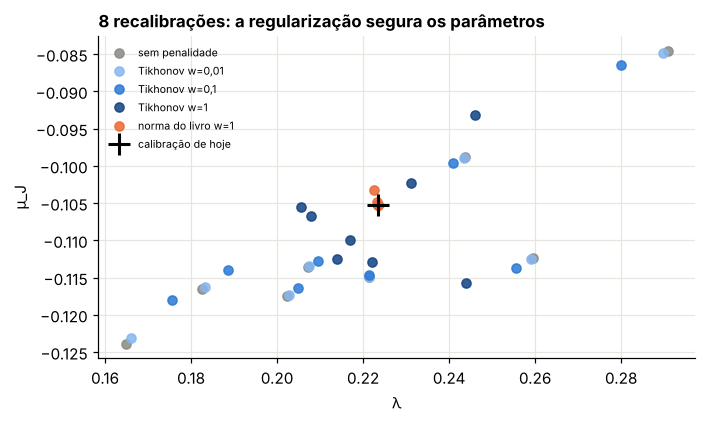

OK — Tikhonov com w = 1 reduz a dispersão de λ a menos da metade
OK — pagando menos de 50% a mais de EQM
OK — a norma do livro, com w = 1, praticamente não deixa os parâmetros se moverem
OK — e o ajuste piora mais de 20% em relação a Tikhonov: a calibração vira 'repetir ontem'


In [9]:
rng = np.random.default_rng(1)
J_HOJE = P_JOINT[5:]
alvos = [np.round(C_JUSTO[CURTO] + rng.normal(0, 0.1, 5), 1) for _ in range(8)]
t0 = time.time()
linhas, dispersao = [], {}
for nome, pen, w in [("sem penalidade", None, 0.0), ("Tikhonov w=0,01", "quad", 0.01),
                     ("Tikhonov w=0,1", "quad", 0.1), ("Tikhonov w=1", "quad", 1.0),
                     ("norma do livro w=1", "norma", 1.0)]:
    sols, erros = [], []
    for a in alvos:
        j = fmin(eqm_saltos, J_HOJE, args=(SV_J, a, pen, w, J_HOJE), xtol=1e-7, ftol=1e-9,
                 maxiter=1500, maxfun=2000, disp=False)
        sols.append(j)
        erros.append(eqm_saltos(j, SV_J, a))
    sols = np.array(sols)
    dispersao[nome] = sols
    linhas.append((nome, *sols.std(axis=0), np.mean(erros)))
tab4 = pd.DataFrame(linhas, columns=["regularização", "desvio de λ", "desvio de μ_J", "desvio de δ", "EQM médio"])
tabela(tab4)
print(f"tempo: {time.time() - t0:.1f} s")

fig, ax = plt.subplots(figsize=(7, 3.8))
for (nome, sols), cor in zip(dispersao.items(), [CINZA, RAMPA[0], RAMPA[1], RAMPA[2], LARANJA]):
    ax.plot(sols[:, 0], sols[:, 1], "o", color=cor, label=nome, alpha=0.85)
ax.plot(*J_HOJE[:2], "k+", ms=14, mew=2, label="calibração de hoje")
ax.set_xlabel("λ"); ax.set_ylabel("μ_J")
ax.set_title("8 recalibrações: a regularização segura os parâmetros")
ax.legend(fontsize=7); plt.show()

t4 = tab4.set_index("regularização")
ok(t4.loc["Tikhonov w=1", "desvio de λ"] < t4.loc["sem penalidade", "desvio de λ"] / 2,
   "Tikhonov com w = 1 reduz a dispersão de λ a menos da metade")
ok(t4.loc["Tikhonov w=1", "EQM médio"] < 1.5 * t4.loc["sem penalidade", "EQM médio"],
   "pagando menos de 50% a mais de EQM")
ok(t4.loc["norma do livro w=1", "desvio de λ"] < 0.005, "a norma do livro, com w = 1, praticamente não deixa os parâmetros se moverem")
ok(t4.loc["norma do livro w=1", "EQM médio"] > 1.2 * t4.loc["Tikhonov w=1", "EQM médio"],
   "e o ajuste piora mais de 20% em relação a Tikhonov: a calibração vira 'repetir ontem'")

**O que aprendemos.** A regularização é uma troca explícita entre estabilidade e ajuste, controlada por $w$. Sem ela, um tick de ruído move $\lambda$ e $\mu_J$ ao longo do vale da Seção 3.1. Com Tikhonov e $w$ moderado, os parâmetros ficam perto dos de ontem, e o ajuste piora pouco. Com a norma do livro e $w = 1$, a penalidade exata da Seção 1.3 entra em ação: a calibração devolve o ponto de partida. A escolha de $w$ deve ser documentada e testada, como qualquer outro parâmetro do modelo.

---
## 5. Calibrar a volatilidades implícitas

**Livro: §11.4.6 e §11.6.6**

O livro recalibra o BCC97 com a função (11.4), o erro de volatilidade ponderado pelo vega, partindo do ajuste em preços. Cada avaliação exige inverter o BSM 15 vezes.

Pelo Módulo 13, Seção 2.1, (11.4) é (11.1) a menos de termos de segunda ordem. Calibrar a (11.4) deveria, portanto, dar quase o mesmo resultado. Para ver uma diferença real, comparamos também com (11.3), o erro de volatilidade **sem** peso, que trata igualmente todos os pontos da superfície.

### Laboratório 5 — (11.1), (11.4) e (11.3)

In [10]:
def ivs_modelo(p):
    C = precos_bcc(p)
    return np.array([vol_impl(c, S0, k, t, r) for c, k, t, r in zip(C, K_OP, T_OP, R_OP)])


def erro_vol(p, ponderado):
    if not admissivel(p, False):
        return 5000.0
    iv = ivs_modelo(p)
    if np.isnan(iv).any():
        return 5000.0
    d = iv - IV_MERC
    return np.mean((d * VEGA) ** 2) if ponderado else np.mean((100 * d) ** 2)


t0 = time.time()
P_114 = fmin(erro_vol, P_JOINT, args=(True,), xtol=1e-6, ftol=1e-8, maxiter=450, maxfun=650, disp=False)
P_113 = fmin(erro_vol, P_JOINT, args=(False,), xtol=1e-6, ftol=1e-8, maxiter=450, maxfun=650, disp=False)
print(f"tempo: {time.time() - t0:.1f} s")

linhas = []
for nome, p in [("preços (11.1)", P_JOINT), ("vol. × vega (11.4)", P_114), ("vol. sem peso (11.3)", P_113)]:
    d = ivs_modelo(p) - IV_MERC
    linhas.append((nome, *p, eqm_bcc(p), erro_vol(p, True), 100 * np.abs(d[CURTO]).max(), 100 * np.abs(d[~CURTO]).max()))
tab5 = pd.DataFrame(linhas, columns=["função objetivo", *NOMES, "(11.1)", "(11.4)",
                                     "maior erro vol. 17d (p.p.)", "maior erro vol. 80/171d (p.p.)"])
tabela(tab5)

t5 = tab5.set_index("função objetivo")
ok(np.abs(P_114 - P_JOINT).max() < 0.2, "(11.4) parte do ajuste em preços e quase não o altera")
ok(abs(t5.loc["vol. × vega (11.4)", "(11.4)"] / t5.loc["preços (11.1)", "(11.4)"]) > 0.5,
   "o ganho em (11.4) é pequeno: as duas funções medem quase a mesma coisa")
ok(t5.loc["vol. sem peso (11.3)", "maior erro vol. 17d (p.p.)"] <= t5.loc["preços (11.1)", "maior erro vol. 17d (p.p.)"] + 1e-6,
   "(11.3) dá mais peso ao prazo curto e não piora o maior erro de volatilidade de 17 dias")

tempo: 30.6 s


,função objetivo,κ_v,θ_v,σ_v,ρ,v0,λ,μ_J,δ,(11.1),(11.4),maior erro vol. 17d (p.p.),maior erro vol. 80/171d (p.p.)
0,preços (11.1),"2,845","0,040","0,500","-0,702","0,030","0,223","-0,105","0,109","0,001","0,001","0,042","0,005"
1,vol. × vega (11.4),"2,829","0,040","0,500","-0,695","0,030","0,196","-0,123","0,102","0,000","0,000","0,017","0,007"
2,vol. sem peso (11.3),"2,988","0,039","0,490","-0,711","0,030","0,191","-0,123","0,112","0,001","0,001","0,015","0,009"


OK — (11.4) parte do ajuste em preços e quase não o altera
OK — o ganho em (11.4) é pequeno: as duas funções medem quase a mesma coisa
OK — (11.3) dá mais peso ao prazo curto e não piora o maior erro de volatilidade de 17 dias


O livro relata que, ao passar de (11.1) para (11.4), $\kappa_v$ vai de 22,2 para 28,5 e $\sigma_v$ de 0,95 para 1,18, com EQM ponderado de 0,083. Se as duas funções são quase iguais, essa mudança de parâmetros é mais um sinal do vale largo do Módulo 13: os parâmetros andam sem que o ajuste mude. Aqui, com dados que de fato vêm do modelo, os três ajustes ficam todos no nível do ruído.

---
## 6. O que a calibração não fixa: risco de modelo

Conjuntos de parâmetros que ajustam igualmente bem as 15 opções podem discordar sobre produtos **fora** da amostra de calibração. Além dos ajustes das seções anteriores, recalibramos o BCC97 com $\kappa_v$ fixo em 1,5 e em 6 (como no perfil do Módulo 13). Medimos três produtos:

* call no dinheiro de 1 ano e de 5 anos (fora dos vencimentos calibrados), em volatilidade implícita;
* **swap de variância** de 5 anos: paga a variância realizada anualizada contra um preço fixo. O preço justo é a variação quadrática esperada. Num modelo com volatilidade de Heston e saltos de Merton:

$$K_{var}(T) = \frac1T\,\mathbb{E}\Big[\int_0^Tv_t\,dt\Big] + \lambda\,\mathbb{E}[J^2] = \theta_v + (v_0 - \theta_v)\frac{1 - e^{-\kappa_vT}}{\kappa_vT} + \lambda(\mu_J^2 + \delta^2).$$

O primeiro termo usa $\mathbb{E}[v_t] = \theta_v + (v_0 - \theta_v)e^{-\kappa_vt}$ (Módulo 11); o segundo soma o quadrado de cada salto, que entra integralmente na variância realizada.

### Laboratório 6 — Mesmo ajuste, preços diferentes

,parâmetros,EQM nas 15 calls,vol. impl. ATM 1 ano (%),vol. impl. ATM 5 anos (%),swap de variância 5 anos (vol. %)
0,verdade,"0,001","19,816","21,015","21,026"
1,Heston (Feller),"0,093","19,916","21,192","21,112"
2,BCC97 sequencial (livro),"0,093","19,916","21,192","21,112"
3,BCC97 conjunto,"0,001","19,820","21,090","21,123"
4,BCC97 em (11.3),"0,001","19,792","20,956","20,963"
5,BCC97 com Feller,"0,004","19,767","20,648","20,647"
6,"BCC97 com κ_v = 1,5","0,012","19,994","22,494","23,114"
7,BCC97 com κ_v = 6,"0,038","19,788","20,681","20,827"


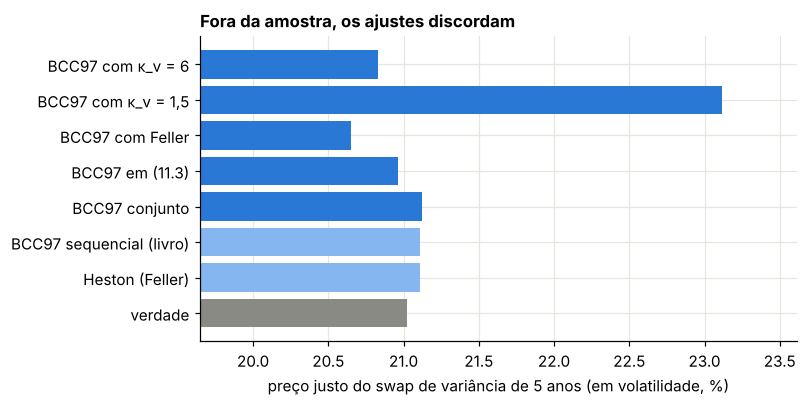

conjuntos com EQM < 0,05: ['verdade', 'BCC97 conjunto', 'BCC97 em (11.3)', 'BCC97 com Feller', 'BCC97 com κ_v = 1,5', 'BCC97 com κ_v = 6']
amplitude entre eles — ATM 1 ano: 0,228 p.p. | swap de variância 5 anos: 2,466 p.p.
OK — com κ_v = 1,5 o ajuste fica em torno de um tick²: indistinguível da verdade
OK — entre ajustes com EQM < 0,05, o swap de variância de 5 anos varia mais de 1,5 ponto de volatilidade
OK — mais de três vezes a variação da call ATM de 1 ano


In [11]:
def k_var(p, T):
    kappa, theta, sigma, rho, v0, lam, mu, delta = p
    return theta + (v0 - theta) * (1 - np.exp(-kappa * T)) / (kappa * T) + lam * (mu**2 + delta**2)


# dois ajustes alternativos: κ_v fixo e os outros 7 parâmetros recalibrados (como o perfil do Módulo 13)
alternativos = {}
for kf in (1.5, 6.0):
    q = fmin(lambda q: eqm_bcc(np.r_[kf, q]), P_JOINT[1:], xtol=1e-6, ftol=1e-6, maxiter=2000, maxfun=3000, disp=False)
    alternativos[kf] = np.r_[kf, q]

conjuntos = {"verdade": VERDADE,
             "Heston (Feller)": np.r_[H93_CAL, 0.0, -0.1, 0.0],
             "BCC97 sequencial (livro)": P_SEQ,
             "BCC97 conjunto": P_JOINT,
             "BCC97 em (11.3)": P_113,
             "BCC97 com Feller": resultados[("chute com saltos", "com Feller")],
             "BCC97 com κ_v = 1,5": alternativos[1.5],
             "BCC97 com κ_v = 6": alternativos[6.0]}
r_long = 0.04
linhas = []
for nome, p in conjuntos.items():
    kappa, theta, sigma, rho, v0, lam, mu, delta = p
    ivs_fora = []
    for T in (1.0, 5.0):
        c = calls(S0, [S0], [T], [r_long], (v0, kappa, theta, sigma, rho), (lam, mu, delta), U_FINO)[0]
        ivs_fora.append(100 * vol_impl(c, S0, S0, T, r_long))
    linhas.append((nome, eqm_bcc(p), *ivs_fora, 100 * np.sqrt(k_var(p, 5.0))))
tab6 = pd.DataFrame(linhas, columns=["parâmetros", "EQM nas 15 calls", "vol. impl. ATM 1 ano (%)",
                                     "vol. impl. ATM 5 anos (%)", "swap de variância 5 anos (vol. %)"])
tabela(tab6)

fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(tab6))
ax.barh(y, tab6["swap de variância 5 anos (vol. %)"], color=[CINZA] + [AZUL if e < 0.05 else RAMPA[0] for e in tab6["EQM nas 15 calls"][1:]])
ax.set_yticks(y, tab6["parâmetros"])
ax.set_xlim(tab6["swap de variância 5 anos (vol. %)"].min() - 1, tab6["swap de variância 5 anos (vol. %)"].max() + 0.5)
ax.set_xlabel("preço justo do swap de variância de 5 anos (em volatilidade, %)")
ax.set_title("Fora da amostra, os ajustes discordam")
plt.show()

t6 = tab6.set_index("parâmetros")
bons = t6[t6["EQM nas 15 calls"] < 0.05]
amp5 = bons["swap de variância 5 anos (vol. %)"].max() - bons["swap de variância 5 anos (vol. %)"].min()
amp1 = bons["vol. impl. ATM 1 ano (%)"].max() - bons["vol. impl. ATM 1 ano (%)"].min()
print("conjuntos com EQM < 0,05:", list(bons.index))
print("amplitude entre eles — ATM 1 ano:", f3(amp1), "p.p. | swap de variância 5 anos:", f3(amp5), "p.p.")
ok(t6.loc["BCC97 com κ_v = 1,5", "EQM nas 15 calls"] < 0.02, "com κ_v = 1,5 o ajuste fica em torno de um tick²: indistinguível da verdade")
ok(amp5 > 1.5, "entre ajustes com EQM < 0,05, o swap de variância de 5 anos varia mais de 1,5 ponto de volatilidade")
ok(amp5 > 3 * amp1, "mais de três vezes a variação da call ATM de 1 ano")

Barras escuras: conjuntos que ajustam as 15 calls com EQM abaixo de 0,05; claras: os que ajustam pior (os dois que pararam no Heston).

**O que aprendemos.** As 15 opções, todas com até seis meses, fixam bem o que acontece até seis meses e pouco além. O ajuste com $\kappa_v = 1{,}5$ tem EQM de cerca de um tick ao quadrado, indistinguível da verdade com essas cotações, e ainda assim põe o swap de variância de 5 anos uns 2 pontos de volatilidade acima. O swap de variância de 5 anos depende de $\theta_v$, de $\kappa_v$ e do termo dos saltos, justamente o que a calibração identifica mal. A distância entre os conjuntos é uma medida direta do **risco de modelo de calibração**: para validar um modelo usado em prazos longos, não basta olhar o ajuste aos dados de calibração.

---
## 7. Síntese

| Etapa | Lição |
|---|---|
| Regularização | Tikhonov (quadrado) troca ajuste por estabilidade de forma suave; a norma (11.17) é uma penalidade exata que pode congelar os parâmetros |
| Saltos sequenciais | sobre um Heston já calibrado, os saltos não entram: o Heston absorveu o skew curto |
| BCC97 completo | uma única busca local herda o mínimo local da partida; várias partidas e a remoção de Feller levam ao ajuste no nível do ruído |
| Degenerescência | $\lambda$ e $\mu_J$ se compensam; o produto é bem identificado, cada um não |
| Volatilidades implícitas | (11.4) ≈ (11.1); a diferença real é para (11.3) |
| Risco de modelo | ajustes equivalentes discordam fora da amostra, mais em prazos longos e em produtos de variância |

## 8. Erratas e notas sobre o capítulo 11 (segunda parte)

| Onde | O quê |
|---|---|
| §11.6.4, `BCC_calibration_short` | `opt1` e `local_opt` são atribuídos sem `global`: viram variáveis locais, e a penalidade da função objetivo nunca é aplicada |
| Eq. (11.17) | a penalidade é a norma $\lVert p - p_0\rVert$, não o quadrado: não é Tikhonov; com $w = 1$ e EQM em pontos², congela os parâmetros no ponto de partida |
| §11.4.4, resultados | $\lambda = 0{,}008$, $\mu_J = -0{,}600$ (no limite) e $\delta = 0{,}001$: na prática, nenhum salto; sintoma da calibração sequencial |
| §11.4.5, resultados | $\rho = -0{,}999$ e $\delta = 0{,}000$ na fronteira, $\lambda = 0{,}008$: o BCC97 calibrado é praticamente um Heston |
| §11.4.6, resultados | $\kappa_v$ vai de 22,2 a 28,5 entre (11.1) e (11.4), funções quase iguais: parâmetros mal identificados; $\mu_J = -0{,}600$ de novo no limite |
| §11.6.5 e §11.6.6 | a condição de Feller continua imposta (ver Módulo 13) |
| §11.6.2 e seguintes | Nelder-Mead com restrições por "valor alto" pode parar cedo encostado numa parede; sem reinício, o resultado depende de detalhes mínimos dos dados |
| §11.6.6 | `options.ix` foi removido do pandas; use `.loc` |

## 9. Exercícios

**Exercício 1.** Mostre que, para $F$ diferenciável e $w > 0$, a solução de Tikhonov $p^*(w)$ satisfaz $\nabla F(p^*) = -2w(p^* - p_0)$. O que isso diz sobre a distância $\lVert p^* - p_0\rVert$ quando $w \to \infty$?

<details><summary>Solução</summary>

É a condição de primeira ordem. Tomando normas, $\lVert p^* - p_0\rVert = \lVert\nabla F(p^*)\rVert/(2w)$, que vai a zero como $1/w$: a solução se aproxima de $p_0$ suavemente, sem nunca "travar", ao contrário da norma.
</details>

**Exercício 2.** Corrija o script do livro para que a penalidade funcione (declare `global opt1, local_opt` em `BCC_calibration_short`) e troque a norma pelo quadrado. Qual $w$ você escolheria para EQM medido em pontos²?

<details><summary>Solução</summary>

Um critério prático: escolha $w$ para que a penalidade, numa variação típica dos parâmetros (digamos 0,05 em cada um), seja comparável ao ruído do EQM (da ordem de $\text{tick}^2$). Com tick de 0,1, $w \cdot 3 \cdot 0{,}05^2 \approx 0{,}01$ dá $w \approx 1$. O Laboratório 4 mostra que esse valor reduz a dispersão a menos da metade, com perda pequena de ajuste.
</details>

**Exercício 3.** Repita o Laboratório 3 com 10 partidas aleatórias (uniformes nas caixas da grade do livro, com $\lambda \in [0, 0{,}5]$). Quantas chegam ao nível do ruído?

<details><summary>Solução</summary>

Depende da semente; em geral, só uma parte delas. Esse "multi-start" é a forma mais simples de busca global; alternativas são `differential_evolution` e `basinhopping` do SciPy. Guarde todos os mínimos encontrados: se vários têm o mesmo erro e parâmetros diferentes, você tem uma medida da degenerescência.
</details>

**Exercício 4.** Deduza a fórmula do swap de variância. Por que a correlação $\rho$ não aparece?

<details><summary>Solução</summary>

A variação quadrática de $\ln S$ é $\int_0^Tv_t\,dt + \sum J_i^2$. A esperança do primeiro termo vem de $\mathbb{E}[v_t]$; a do segundo é $\lambda T\,\mathbb{E}[J^2] = \lambda T(\mu_J^2 + \delta^2)$. A correlação afeta a distribuição conjunta de $S$ e $v$, mas não a média de $v$, e o swap só depende dessa média.
</details>

In [12]:
print(f"Módulo 14 concluído: {_checks['n']} verificações aprovadas.")

Módulo 14 concluído: 24 verificações aprovadas.
